# Assignment 4 — Tree ensembles

## Research questions

1. On the same held-out split as Assignment 2, do Random Forest and XGBoost improve ten-class attack-category classification over the ordinary decision tree? Which ensemble has the best macro-F1, with accuracy and balanced accuracy as supporting measures?
2. Does class weighting improve Random Forest's ten-class and attack-detection performance?
3. When predictions are collapsed to attack versus normal, which model best catches attacks, and what false-positive rate does that require? Compare attack recall, precision, F1, and false-positive rate together; high recall alone is not enough.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, RobustScaler
import sys

## Load and clean the data

In [2]:
DATA_PATHS = [Path('networkTraffic.csv'), Path('assignments/assign4/code/networkTraffic.csv')]
DATA_PATH = next((path for path in DATA_PATHS if path.exists()), None)
tree_df = pd.read_csv(DATA_PATH, na_values=['?'], skipinitialspace=True)
tree_df['service'] = tree_df['service'].fillna('MISSING')
tree_df['state'] = tree_df['state'].replace('no', 'NOT_USED')
tree_y = tree_df['attack_cat']

## Reproduce the Assignment 2 split and feature sets

In [3]:
tree_dev_idx, tree_test_idx = train_test_split(
    np.arange(len(tree_y)),
    test_size=0.2,
    random_state=42,
    stratify=tree_y,
)

remove_features = [
    'id', 'service', 'sbytes', 'sloss', 'dbytes', 'dloss',
    'dwin', 'synack', 'ackdat', 'ct_dst_ltm',
    'ct_src_dport_ltm', 'ct_dst_src_ltm', 'ct_srv_dst',
    'ct_ftp_cmd',
]
tree_reduced_remove = [feature for feature in remove_features if feature != 'service']
tree_feature_sets = {
    'tree_full': [column for column in tree_df if column not in ['id', 'attack_cat']],
    'tree_reduced': [column for column in tree_df if column not in tree_reduced_remove + ['id', 'attack_cat']],
}
tree_datasets = {
    name: tree_df[columns].copy() for name, columns in tree_feature_sets.items()
}

FEATURE_SET = 'tree_full'
X = tree_datasets[FEATURE_SET]
X_train = X.iloc[tree_dev_idx].copy()
X_test = X.iloc[tree_test_idx].copy()
y_train = tree_y.iloc[tree_dev_idx].copy()
y_test = tree_y.iloc[tree_test_idx].copy()

## Apply the Assignment 2 tree preprocessing

In [4]:
tree_categorical = ['proto', 'state', 'service']

def make_tree_preprocessor(X, scale_numeric=False):
    categorical = [column for column in tree_categorical if column in X.columns]
    numeric = [column for column in X.columns if column not in categorical]
    numeric_transformer = RobustScaler() if scale_numeric else 'passthrough'
    categorical_transformer = OneHotEncoder(
        handle_unknown='ignore', sparse_output=True
    )
    return ColumnTransformer([
        ('numeric', numeric_transformer, numeric),
        ('categorical', categorical_transformer, categorical),
    ])

preprocessor = make_tree_preprocessor(X_train)
X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

## Dense arrays for XGBoost

In [5]:
X_train_dense = X_train_ready.astype(np.float32).toarray()
X_test_dense = X_test_ready.astype(np.float32).toarray()

## Checkpoint setup

In [6]:
CODE_DIR = DATA_PATH.resolve().parent
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from ensemble_experiment import (
    completed_results, load_final_table, log, prepare_run, rf_finalist_configs,
    rf_grid, run_final_models, run_rf_candidates, run_xgb_candidates,
    selected_rf_results, selected_xgb_result, xgb_grid,
)

RUN_ROOT = CODE_DIR / 'results' / f'{FEATURE_SET}_split42_v1'
RUN_ROOT = prepare_run(
    RUN_ROOT, DATA_PATH, FEATURE_SET, X.columns, tree_dev_idx, tree_test_idx
)
RF_SCREEN_TREES = 100
RF_FINAL_TREES = 300
N_JOBS = 4 
RF_GRID = rf_grid()
XGB_GRID = xgb_grid()
log(f'{len(RF_GRID)} forest screening candidates; {len(XGB_GRID)} XGBoost candidates')

[2026-10-11T10:38:40+02:00] Run directory ready: /home/algor/onedrive/Documents/University/Honours/sem-2/machine-learning/assignments/assign4/code/results/tree_full_split42_v1
[2026-10-11T10:38:40+02:00] 24 forest screening candidates; 8 XGBoost candidates


## 1. Random Forest: ordinary versus weighted

In [7]:
RUN_RF_SEARCH = True

if RUN_RF_SEARCH:
    rf_results = run_rf_candidates(
        RUN_ROOT, X_train_ready, y_train, RF_GRID, RF_SCREEN_TREES, n_jobs=N_JOBS
    )
    finalist_configs = rf_finalist_configs(rf_results, RF_SCREEN_TREES)
    log(f'Forest finalists selected from OOB screening: {finalist_configs}')
    rf_results = run_rf_candidates(
        RUN_ROOT, X_train_ready, y_train, finalist_configs, RF_FINAL_TREES, n_jobs=N_JOBS
    )
else:
    rf_results = completed_results(RUN_ROOT / 'rf')
    log('RF search is off; displaying saved candidates only')

rf_table = pd.DataFrame([
    {'id': row['id'], **row['config'], 'oob_macro_f1': row['oob_macro_f1'],
     'oob_accuracy': row['oob_accuracy'], 'oob_coverage': row['oob_coverage'],
     'minutes': row['elapsed_seconds'] / 60}
    for row in rf_results
])
if len(rf_table):
    display(rf_table.sort_values('oob_macro_f1', ascending=False))
else:
    log('No completed RF candidates yet')

[2026-10-11T10:38:41+02:00] RF 1/24 skip completed rf-f937295befca: {'class_weight': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
[2026-10-11T10:38:41+02:00] RF 2/24 skip completed rf-846a50b5fa31: {'class_weight': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 100}
[2026-10-11T10:38:41+02:00] RF 3/24 skip completed rf-c6865a41fb64: {'class_weight': None, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 100}
[2026-10-11T10:38:41+02:00] RF 4/24 skip completed rf-c7e16d8127e7: {'class_weight': None, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 100}
[2026-10-11T10:38:41+02:00] RF 5/24 skip completed rf-b14b44f87abd: {'class_weight': None, 'max_features': 0.25, 'min_samples_leaf': 1, 'n_estimators': 100}
[2026-10-11T10:38:41+02:00] RF 6/24 skip completed rf-a84174030491: {'class_weight': None, 'max_features': 0.25, 'min_samples_leaf': 5, 'n_estimators': 100}
[2026-10-11T10:38:41+02:00] RF 7/24 skip complet

,id,class_weight,max_features,min_samples_leaf,n_estimators,oob_macro_f1,oob_accuracy,oob_coverage,minutes
17,rf-97e1996df187,NaN,0.5,1,300,0.604855,0.832535,1.0,11.483043
3,rf-254ce2a1f700,NaN,0.5,1,100,0.604530,0.831079,1.0,3.908979
12,rf-6bb70bc41289,NaN,0.5,5,100,0.597504,0.829794,1.0,2.850160
9,rf-45245837bbed,balanced_subsample,0.5,5,300,0.596905,0.795443,1.0,8.547361
6,rf-39a44890cb5b,balanced_subsample,0.5,5,100,0.596831,0.794012,1.0,2.883678
1,rf-111937b7dc42,balanced_subsample,0.5,1,100,0.594696,0.802671,1.0,4.070821
20,rf-b14b44f87abd,NaN,0.25,1,100,0.591782,0.829750,1.0,2.465552
2,rf-2157f5338cdd,balanced_subsample,0.25,1,100,0.588701,0.801182,1.0,2.798962
5,rf-2c784182c83e,balanced_subsample,0.25,5,100,0.588090,0.788874,1.0,1.776581
8,rf-42670d3c4618,NaN,0.5,10,100,0.578314,0.828154,1.0,2.453875


## 2. XGBoost

In [18]:
xgb_fit_idx, xgb_validation_idx = train_test_split(
    np.arange(len(y_train)), test_size=0.2, random_state=43, stratify=y_train
)
log(f'XGBoost stratified split: {len(xgb_fit_idx):,} fit / {len(xgb_validation_idx):,} validation rows')

RUN_XGB_SEARCH = True
if RUN_XGB_SEARCH:
    xgb_results = run_xgb_candidates(
        RUN_ROOT, X_train_dense, y_train, xgb_fit_idx, xgb_validation_idx,
        XGB_GRID, max_rounds=600, patience=30, n_jobs=N_JOBS,
    )
else:
    xgb_results = completed_results(RUN_ROOT / 'xgb')
    log('XGBoost search is off; displaying saved candidates only')

xgb_table = pd.DataFrame([
    {'id': row['id'], 'max_depth': row['config']['max_depth'],
     'min_child_weight': row['config']['min_child_weight'],
     'learning_rate': row['config']['learning_rate'],
     'best_rounds': row['best_iteration'] + 1,
     'validation_macro_f1': row['validation_macro_f1'],
     'validation_mlogloss': row['validation_mlogloss'],
     'minutes': row['elapsed_seconds'] / 60}
    for row in xgb_results
])
if len(xgb_table):
    display(xgb_table.sort_values('validation_macro_f1', ascending=False))
else:
    log('No completed XGBoost candidates yet')

[2026-10-11T10:06:35+02:00] XGBoost stratified split: 164,910 fit / 41,228 validation rows
[2026-10-11T10:06:35+02:00] XGB 1/8 skip completed xgb-f6ca3cb851a5: {'max_depth': 3, 'min_child_weight': 1, 'learning_rate': 0.05}
[2026-10-11T10:06:35+02:00] XGB 2/8 skip completed xgb-b4f5a9dd0c78: {'max_depth': 3, 'min_child_weight': 1, 'learning_rate': 0.1}
[2026-10-11T10:06:35+02:00] XGB 3/8 skip completed xgb-73a974e206b4: {'max_depth': 3, 'min_child_weight': 10, 'learning_rate': 0.05}
[2026-10-11T10:06:35+02:00] XGB 4/8 skip completed xgb-90a7bdd90841: {'max_depth': 3, 'min_child_weight': 10, 'learning_rate': 0.1}
[2026-10-11T10:06:35+02:00] XGB 5/8 skip completed xgb-fa812878c95e: {'max_depth': 6, 'min_child_weight': 1, 'learning_rate': 0.05}
[2026-10-11T10:06:35+02:00] XGB 6/8 skip completed xgb-7f15e21197cb: {'max_depth': 6, 'min_child_weight': 1, 'learning_rate': 0.1}
[2026-10-11T10:06:35+02:00] XGB 7/8 skip completed xgb-26ccb77e2cce: {'max_depth': 6, 'min_child_weight': 10, 'learnin

,id,max_depth,min_child_weight,learning_rate,best_rounds,validation_macro_f1,validation_mlogloss,minutes
1,xgb-4d1252ea89d3,6,10,0.10,479,0.606350,0.399516,1.858247
3,xgb-7f15e21197cb,6,1,0.10,360,0.603228,0.399606,1.570422
7,xgb-fa812878c95e,6,1,0.05,600,0.602279,0.398985,2.251889
0,xgb-26ccb77e2cce,6,10,0.05,599,0.598396,0.400972,2.265067
5,xgb-b4f5a9dd0c78,3,1,0.10,600,0.593582,0.412759,1.623905
4,xgb-90a7bdd90841,3,10,0.10,600,0.587687,0.413389,1.627964
6,xgb-f6ca3cb851a5,3,1,0.05,600,0.578503,0.426284,1.617455
2,xgb-73a974e206b4,3,10,0.05,600,0.577216,0.427624,1.692969


## 3. Held-out comparison: ten classes

In [19]:
RUN_FINAL_EVALUATION = True

if RUN_FINAL_EVALUATION:
    screening = [row for row in rf_results if row['config']['n_estimators'] == RF_SCREEN_TREES]
    if len(screening) < len(RF_GRID) or len(xgb_results) < len(XGB_GRID):
        raise RuntimeError('Finish all RF screening and XGBoost candidates before evaluating the held-out test set')
    rf_finalists = selected_rf_results(rf_results, RF_FINAL_TREES)
    xgb_finalist = selected_xgb_result(xgb_results)
    log(f'Locked selection will use RF IDs {[row["id"] for row in rf_finalists]} and XGB ID {xgb_finalist["id"]}')
    final_table = run_final_models(
        RUN_ROOT, X_train_ready, X_train_dense, X_test_ready, X_test_dense,
        y_train, y_test, rf_finalists, xgb_finalist, n_jobs=N_JOBS,
    )
else:
    final_table = load_final_table(RUN_ROOT)
    log('Final evaluation is off; displaying saved held-out results only')

if len(final_table):
    display(final_table[['model', 'macro_f1', 'accuracy', 'balanced_accuracy', 'mcc', 'elapsed_seconds']].sort_values('macro_f1', ascending=False))
else:
    log('No saved held-out results yet')

import json
baseline_path = CODE_DIR.parents[1] / 'assign2' / 'final-held-out-test-metrics.json'
if baseline_path.exists():
    with baseline_path.open(encoding='utf-8') as stream:
        baseline = next(row for row in json.load(stream) if row['model'] == 'Ordinary tree')
    log('Assignment 2 ordinary-tree reference (same held-out split):')
    display(pd.DataFrame([baseline])[['model', 'macro_f1', 'accuracy', 'balanced_accuracy', 'mcc']])
else:
    log(f'Assignment 2 reference file not found: {baseline_path}')

[2026-10-11T10:06:39+02:00] Locked selection will use RF IDs ['rf-97e1996df187', 'rf-45245837bbed'] and XGB ID xgb-4d1252ea89d3
[2026-10-11T10:06:39+02:00] Final random_forest: loaded saved test result
[2026-10-11T10:06:39+02:00] Final weighted_random_forest: loaded saved test result
[2026-10-11T10:06:39+02:00] Final xgboost: loaded saved test result


,model,macro_f1,accuracy,balanced_accuracy,mcc,elapsed_seconds
0,random_forest,0.608979,0.830232,0.578611,0.779088,699.040306
2,xgboost,0.603775,0.833453,0.584798,0.784570,120.550194
1,weighted_random_forest,0.602878,0.792394,0.657242,0.739674,544.337644


[2026-10-11T10:06:39+02:00] Assignment 2 ordinary-tree reference (same held-out split):


,model,macro_f1,accuracy,balanced_accuracy,mcc
0,Ordinary tree,0.588872,0.748967,0.687964,0.700227


## 4. Held-out comparison: attack versus normal

In [20]:
binary_columns = [
    'model', 'attack_recall', 'attack_precision', 'attack_f1',
    'false_positive_rate', 'false_positives', 'false_negatives',
    'attack_roc_auc', 'attack_average_precision',
]
if len(final_table):
    display(final_table[binary_columns].sort_values(
        ['attack_recall', 'false_positive_rate'], ascending=[False, True]
    ))
else:
    log('No saved binary comparison yet; complete held-out evaluation above')

if baseline_path.exists():
    baseline_binary = {key: baseline[key] for key in ('model', 'attack_recall', 'attack_precision', 'attack_f1')}
    baseline_binary['false_positive_rate'] = 1 - baseline['normal_specificity']
    log('Assignment 2 ordinary-tree binary reference:')
    display(pd.DataFrame([baseline_binary]))

,model,attack_recall,attack_precision,attack_f1,false_positive_rate,false_positives,false_negatives,attack_roc_auc,attack_average_precision
1,weighted_random_forest,0.974860,0.942300,0.958303,0.105699,1966,828,0.992001,0.995515
0,random_forest,0.953848,0.969599,0.961659,0.052957,985,1520,0.992291,0.995517
2,xgboost,0.947654,0.971488,0.959423,0.049247,916,1724,0.992077,0.995646


[2026-10-11T10:06:47+02:00] Assignment 2 ordinary-tree binary reference:


,model,attack_recall,attack_precision,attack_f1,false_positive_rate
0,Ordinary tree,0.997055,0.867628,0.92785,0.269355


## 5. Post-hoc error diagnostics

[2026-10-11T10:07:00+02:00] Diagnosed random_forest from saved predictions; no fitting performed
[2026-10-11T10:07:00+02:00] Diagnosed weighted_random_forest from saved predictions; no fitting performed
[2026-10-11T10:07:00+02:00] Diagnosed xgboost from saved predictions; no fitting performed
[2026-10-11T10:07:00+02:00] Saved row-normalized confusion matrices: /home/algor/onedrive/Documents/University/Honours/sem-2/machine-learning/assignments/assign4/report/figures/confusion_matrices.pdf
[2026-10-11T10:07:00+02:00] Per-class precision, recall, F1, and support:


,model,class,support,precision,recall,f1
0,random_forest,0,18600,0.920564,0.947043,0.933616
1,random_forest,1,2798,0.930465,0.765189,0.839773
2,random_forest,2,466,0.576471,0.105150,0.177858
3,random_forest,3,3271,0.344179,0.268419,0.301615
4,random_forest,4,8905,0.647743,0.813588,0.721254
5,random_forest,5,535,0.723404,0.127103,0.216216
6,random_forest,6,4849,0.707087,0.619303,0.660290
7,random_forest,7,35,0.739130,0.485714,0.586207
8,random_forest,8,302,0.654839,0.672185,0.663399
9,random_forest,9,11774,0.996811,0.982419,0.989563


[2026-10-11T10:07:00+02:00] Final-stage elapsed time (fit, predict, and save):


,model,final_fit_predict_save_minutes,macro_f1,attack_recall,false_positive_rate
0,random_forest,11.650672,0.608979,0.953848,0.052957
1,weighted_random_forest,9.072294,0.602878,0.974860,0.105699
2,xgboost,2.009170,0.603775,0.947654,0.049247


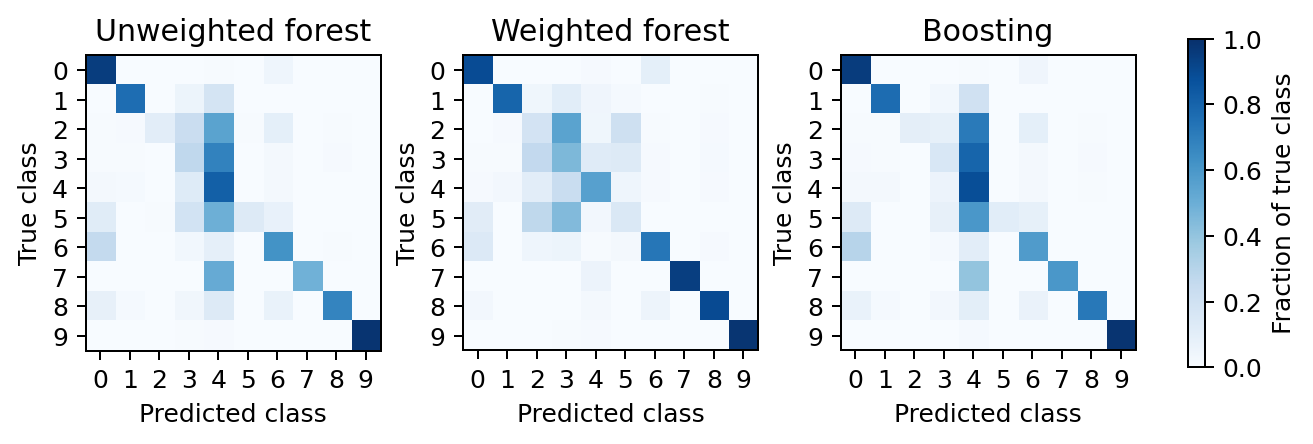

In [21]:
import importlib
import ensemble_experiment
importlib.reload(ensemble_experiment)
from ensemble_experiment import saved_prediction_diagnostics
from IPython.display import Image

FIGURE_PATH = CODE_DIR.parent / 'report' / 'figures' / 'confusion_matrices.pdf'
per_class_table, error_table, runtime_table = saved_prediction_diagnostics(
    RUN_ROOT, y_test, figure_path=FIGURE_PATH
)
log('Per-class precision, recall, F1, and support:')
display(per_class_table)
log('Final-stage elapsed time (fit, predict, and save):')
display(runtime_table)
display(Image(filename=str(FIGURE_PATH.with_suffix('.png'))))

In [22]:
log('Attack errors by true class: predicted normal versus wrong attack subtype')
display(error_table[error_table['class'] != 0][[
    'model', 'class', 'support', 'correct_subtype',
    'missed_as_normal', 'wrong_attack_subtype',
]])

for model_name in ('random_forest', 'weighted_random_forest', 'xgboost'):
    matrix = pd.read_csv(
        RUN_ROOT / 'diagnostics' / f'{model_name}_confusion_counts.csv',
        index_col='true_class',
    )
    top_pairs = []
    for true_class in matrix.index:
        for predicted_class in matrix.columns:
            if int(predicted_class) != int(true_class):
                top_pairs.append((int(matrix.loc[true_class, predicted_class]),
                                  int(true_class), int(predicted_class)))
    log(f'{model_name}: five most frequent off-diagonal confusions (count, true, predicted)')
    print(sorted(top_pairs, reverse=True)[:5])

[2026-10-11T10:07:17+02:00] Attack errors by true class: predicted normal versus wrong attack subtype


,model,class,support,correct_subtype,missed_as_normal,wrong_attack_subtype
1,random_forest,1,2798,2141,8,649
2,random_forest,2,466,49,2,415
3,random_forest,3,3271,878,24,2369
4,random_forest,4,8905,7245,146,1514
5,random_forest,5,535,68,62,405
6,random_forest,6,4849,3003,1244,602
7,random_forest,7,35,17,0,18
8,random_forest,8,302,203,24,75
9,random_forest,9,11774,11567,10,197
11,weighted_random_forest,1,2798,2220,3,575


[2026-10-11T10:07:17+02:00] random_forest: five most frequent off-diagonal confusions (count, true, predicted)
[(2230, 3, 4), (1244, 6, 0), (1101, 4, 3), (851, 0, 6), (486, 1, 4)]
[2026-10-11T10:07:17+02:00] weighted_random_forest: five most frequent off-diagonal confusions (count, true, predicted)
[(2069, 4, 3), (1728, 0, 6), (918, 4, 2), (856, 3, 2), (658, 6, 0)]
[2026-10-11T10:07:17+02:00] xgboost: five most frequent off-diagonal confusions (count, true, predicted)
[(2600, 3, 4), (1435, 6, 0), (791, 0, 6), (556, 1, 4), (503, 6, 4)]
